In [1]:
import pandas as pd
df = pd.read_csv("logs_reseau.csv")
df.head()

,timestamp,src_ip,dst_ip,dst_port,protocol,bytes_sent,duration_s,device_type,action
0,2026-10-05 00:05:13,192.168.1.30,10.0.0.6,80,TCP,7257.0,0.63,capteur_IoT,ALLOW
1,2026-10-05 00:05:43,192.168.1.10,10.0.0.5,80,TCP,1720.0,1.62,capteur_IoT,ALLOW
2,2026-10-05 00:10:45,192.168.1.26,1.1.1.1,1883,TCP,6951.0,4.22,camera_IoT,ALLOW
3,2026-10-05 00:12:25,192.168.1.13,10.0.0.6,80,TCP,3144.0,0.16,capteur_IoT,ALLOW
4,2026-10-05 00:12:34,192.168.1.15,10.0.0.5,8080,TCP,879.0,2.71,serveur,ALLOW


In [2]:
print(df.shape)
print(df.isna().sum())
print(df["protocol"].value_counts())
print(df.duplicated().sum())

(5500, 9)
timestamp        0
src_ip           0
dst_ip           0
dst_port         0
protocol         0
bytes_sent     166
duration_s       0
device_type      0
action           0
dtype: int64
protocol
TCP     4347
UDP      727
tcp      235
ICMP     150
udp       36
icmp       5
Name: count, dtype: int64
60


In [3]:
df = df.drop_duplicates()
df["protocol"] = df["protocol"].str.upper()
df["bytes_sent"] = df["bytes_sent"].fillna(df["bytes_sent"].median())
print(len(df))

5440


### Action 10 : calculer 3 résultats (lignes, port le plus utilisé, taux de DENY)

In [4]:
nb_lignes = len(df)
top_port = df["dst_port"].value_counts().idxmax()
taux_deny = round((df["action"] == "DENY").mean() * 100, 2)

print(nb_lignes)
print(top_port)
print(taux_deny)

5440
443
13.57


### Action 11 : trouver le scanner et l’IP qui envoie le plus de données

In [5]:
ports_par_ip = df.groupby("src_ip")["dst_port"].nunique()
ip_scanner = ports_par_ip.idxmax()

octets_par_ip = df.groupby("src_ip")["bytes_sent"].sum()
ip_exfiltration = octets_par_ip.idxmax()

print(ip_scanner)
print(ports_par_ip.max())
print(ip_exfiltration)
print(octets_par_ip.max())

192.168.1.99
328
192.168.1.11
259932541.0


#### 328 ports, c’est énorme (les autres IP en contactent environ 8). Une IP qui teste autant de ports différents, c’est un scan de ports : quelqu’un cherche quelles portes sont ouvertes.

### Action 12 : enregistrer les 5 résultats dans resultats.json

In [6]:
import json

resultats = {
    "nb_lignes_apres_nettoyage": int(nb_lignes),
    "top_port": int(top_port),
    "taux_deny_pct": float(taux_deny),
    "ip_scanner": str(ip_scanner),
    "ip_exfiltration": str(ip_exfiltration),
}

with open("../resultats.json", "w") as f:
    json.dump(resultats, f, indent=2)

print(resultats)

{'nb_lignes_apres_nettoyage': 5440, 'top_port': 443, 'taux_deny_pct': 13.57, 'ip_scanner': '192.168.1.99', 'ip_exfiltration': '192.168.1.11'}


### Action 13 : créer le dossier figures et le 1er graphique (les ports les plus utilisés)

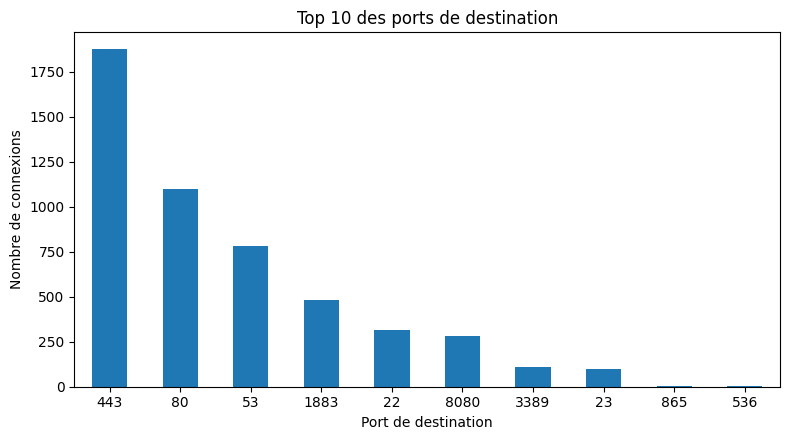

In [7]:
import os
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

top10 = df["dst_port"].value_counts().head(10)

plt.figure(figsize=(8, 4.5))
top10.plot(kind="bar")
plt.title("Top 10 des ports de destination")
plt.xlabel("Port de destination")
plt.ylabel("Nombre de connexions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../figures/top_ports.png")
plt.show()

### Action 14 : 2e graphique (nombre de connexions par jour)

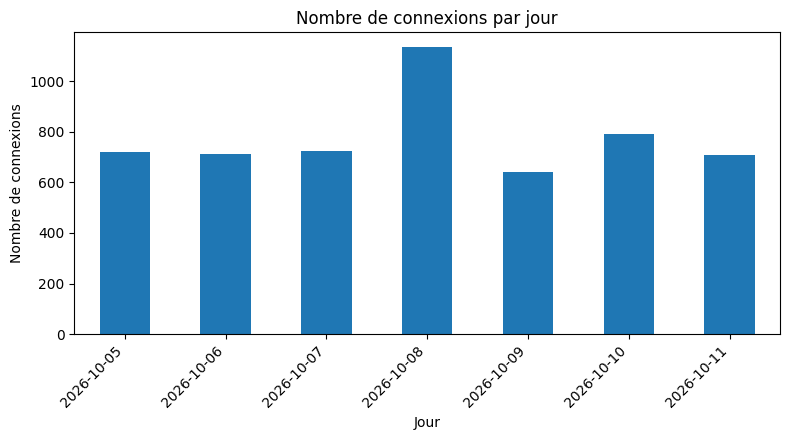

In [8]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
par_jour = df.groupby(df["timestamp"].dt.date).size()

plt.figure(figsize=(8, 4.5))
par_jour.plot(kind="bar")
plt.title("Nombre de connexions par jour")
plt.xlabel("Jour")
plt.ylabel("Nombre de connexions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../figures/connexions_par_jour.png")
plt.show()

### Action 15 : 3e graphique (octets envoyés par type d’appareil)

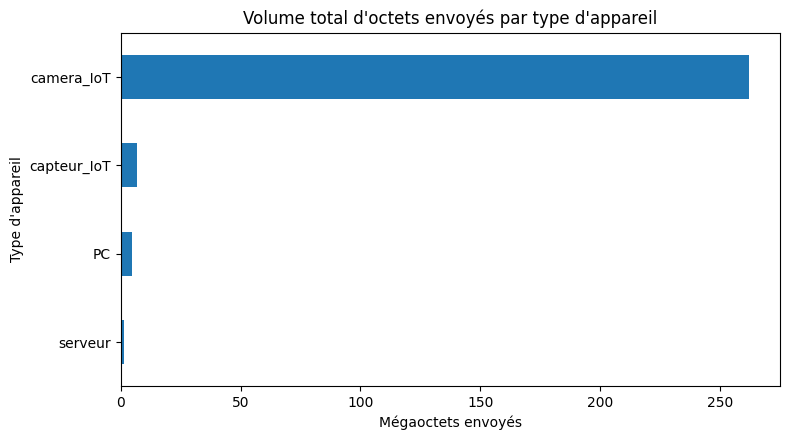

In [9]:
volume = (df.groupby("device_type")["bytes_sent"].sum() / 1e6).sort_values()

plt.figure(figsize=(8, 4.5))
volume.plot(kind="barh")
plt.title("Volume total d'octets envoyés par type d'appareil")
plt.xlabel("Mégaoctets envoyés")
plt.ylabel("Type d'appareil")
plt.tight_layout()
plt.savefig("../figures/octets_par_appareil.png")
plt.show()

### Action 16 : récupérer les preuves chiffrées pour le rapport

In [10]:
scan = df[df["src_ip"] == ip_scanner]
print(len(scan))
print(round((scan["action"] == "DENY").mean() * 100, 2))
print(scan["timestamp"].min(), scan["timestamp"].max())

cam = df[df["src_ip"] == ip_exfiltration]
print(len(cam))
print(round(cam["bytes_sent"].sum() / df["bytes_sent"].sum() * 100, 2))

400
95.75
2026-10-08 00:00:02 2026-10-08 00:14:58
194
94.67


### Action 17 : 4e graphique (répartition ALLOW / DENY)

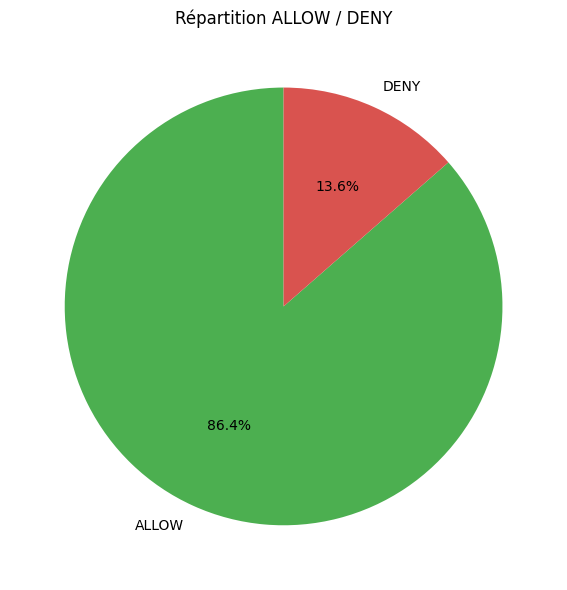

In [12]:
repartition = df["action"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(repartition.values,
        labels=repartition.index,
        autopct="%1.1f%%",
        colors=["#4caf50", "#d9534f"],
        startangle=90)
plt.title("Répartition ALLOW / DENY")
plt.tight_layout()
plt.savefig("../figures/allow_deny.png")
plt.show()